In [25]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score


data=pd.read_csv('seeds_data.csv')
X=data.drop('Class',axis=1).to_numpy()
y=data['Class'].to_numpy()

print(X.shape,y.shape)

(210, 7) (210,)


Function for KMeans

In [24]:
def KMeans(X,K,max_iters=10000):
    #To produce same sequence of random no.s every time the code is run
    np.random.seed(42)
    #For initializing centroids to random points in the data set
    idxs=np.random.choice(len(X),K,replace=False)
    centroids=X[idxs]
    #For finding out new clusters and centroids
    for _ in range(max_iters):
        clusters=[np.argmin([np.linalg.norm(centroids-X) for centroids in centroids]) for X in X]
        centroids_new=np.array([X[np.array(clusters)==i].mean(axis=0) for i in range(K)])
        if np.allclose(centroids_new,centroids):
            break
        centroids=centroids_new
    return np.array(clusters),centroids

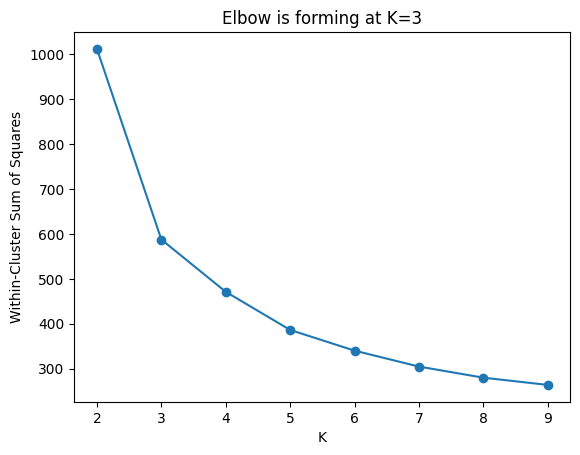

In [23]:
wcss = []
K_range = range(2, 10)

for k in K_range:
    clusters, centers = KMeans(X,k,max_iters=10000)
    wcss.append(sum(np.linalg.norm(X[i] - centers[clusters[i]])**2 for i in range(len(X))))

plt.plot(K_range, wcss, marker='o')
plt.xlabel("K")
plt.ylabel("Within-Cluster Sum of Squares")
plt.title("Elbow is forming at K=3")
plt.show()

In [26]:
k_opt = 3
clusters, centers = KMeans(X, k_opt)

print("\nCluster Centers:")
print(pd.DataFrame(centers))


Cluster Centers:
           0          1         2         3         4         5         6
0  14.648472  14.460417  0.879167  5.563778  3.277903  2.648933  5.192319
1  11.964416  13.274805  0.852200  5.229286  2.872922  4.759740  5.088519
2  18.721803  16.297377  0.885087  6.208934  3.722672  3.603590  6.066098


Visualizing the clusters with the help of PCA dimensionality reduction algorithm

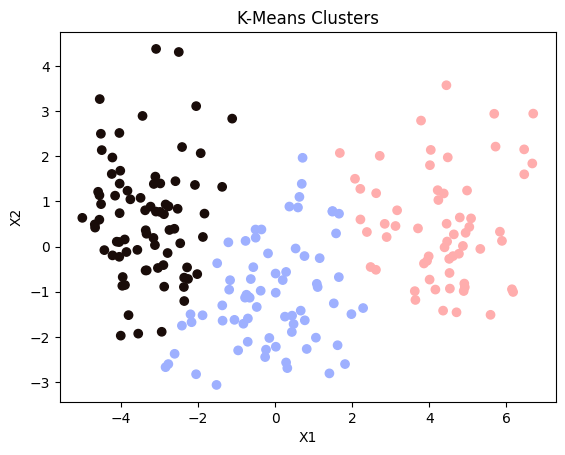

In [20]:
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X)

plt.scatter(X_2d[:,0], X_2d[:,1], c=clusters, cmap="berlin")
plt.xlabel("X1"); plt.ylabel("X2")
plt.title("K-Means Clusters")
plt.show()

Accuracy Metrics

We use the Silhouette score as it measures how similar each data point is to its own cluster compared
to other clusters. It calculates a score for each point which tells us if the point is well-clustered
A higher score means the point is close to its own cluster and far from others.Silhouette score ranges
from -1 to +1.

In [22]:
sil_score=silhouette_score(X, clusters)
print("Silhouette Score: ", sil_score)

Silhouette Score:  0.4719337319126887


A silhouette score of ~0.47 indicates moderate clustering quality — clusters are somewhat separated
but many points lie near cluster boundaries or in poorly shaped clusters.

 Main reasons may be overlapping clusters,noise issues, or non-spherical cluster shapes that K‑means
 can’t capture.


